<a href="https://colab.research.google.com/github/ahmedaeldahmy/AAI-521-Group4-Eurosat/blob/main/notebooks/04_Model_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Evaluation and Comparison: CNN vs. MobileNetV2 vs. EfficientNetB0

**AAI-521, Group 4 | Sai Gautham Bandi** (evaluation and comparison owner)

**Team:** Ahmed Eldahmy (Model A), Akua Duffour (Model B), Sai Gautham Bandi
(Model C)

This notebook does not train anything. It reads the files that each model
notebook saved in `results/` and compares the three models on the **same
4,050 test images**:

| Model | Notebook | Files read |
|---|---|---|
| A: CNN from scratch | `01_Ahmed_EuroSAT_EDA_ModelA.ipynb` | `cnn_from_scratch_*` |
| B: MobileNetV2 (ImageNet) | `02_Akua_MobileNetV2.ipynb` | `mobilenet_*` |
| C: EfficientNetB0 (ImageNet) | `03_Sai_EfficientNetB0.ipynb` | `efficientnet_*` |

It runs in a few seconds on a CPU. The outputs are
`results/model_comparison.csv` and the `comparison_*.png` figures used in the
report and slides.


## 1. Metrics and why we use them

Let $C$ be the $K\times K$ confusion matrix ($K=10$). $C_{ij}$ counts the
test images of true class $i$ that the model predicted as class $j$, and
$N=\sum_{ij}C_{ij}=4050$.

* **Accuracy** $=\frac{1}{N}\sum_k C_{kk}$, the share of tiles labelled
  correctly. It is the headline number, but it gives larger classes more
  weight.
* **Precision** for class $k$: $P_k = C_{kk}/\sum_i C_{ik}$. When the model
  says "River", how often is it right? Low precision means false alarms.
* **Recall** for class $k$: $R_k = C_{kk}/\sum_j C_{kj}$. Of the real
  rivers, how many did it find? Low recall means misses.
* **F1** $=2P_kR_k/(P_k+R_k)$, the harmonic mean, which punishes a class that
  is weak on either side.
* **Macro average** $=\frac1K\sum_k(\cdot)_k$. Every land-cover class counts
  equally. EuroSAT has 300 to 450 test tiles per class, so macro-F1 shows
  whether a model neglects the smaller classes, such as Pasture. A mapping
  agency needs every class to work, so **macro-F1 is our primary selection
  metric**, with accuracy reported next to it.

A single test score is a point estimate. So I also give **bootstrap 95%
confidence intervals** (Section 4) and **hypothesis tests** for the
differences between models (Section 5). The two tests are the two-proportion
$z$-test and McNemar's test. Without them we could not tell a real gap from
test-set noise.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

candidates = [Path("/content/AAI-521-Group4-Eurosat"), Path.cwd(),
              Path.cwd().parent]
REPO = next((p for p in candidates if (p / "results").is_dir()
             and (p / "data" / "split.csv").exists()), None)
if REPO is None:  # Colab without a clone
    import subprocess

    REPO = candidates[0]
    subprocess.run(["git", "clone",
                    "https://github.com/ahmedaeldahmy/AAI-521-Group4-Eurosat.git",
                    str(REPO)], check=True)
RESULTS = REPO / "results"
CLASS_NAMES = json.loads((REPO / "data" / "class_map.json")
                         .read_text())["class_names"]
split_df = pd.read_csv(REPO / "data" / "split.csv")
test_counts = (split_df[split_df["split"] == "test"]["label"]
               .value_counts().sort_index().to_numpy())

MODELS = {  # display name -> file prefix in results/
    "A: CNN (scratch)": "cnn_from_scratch",
    "B: MobileNetV2": "mobilenet",
    "C: EfficientNetB0": "efficientnet",
}
# Categorical colours, fixed per model in every figure (slots 1-3 of a
# colour-blind-checked palette). Heatmaps use a single-hue "Blues" ramp.
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a"]))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
print("Repository:", REPO)

Repository: C:\mycode\msaai521_cv\final_project\project


## 2. Load the results and check that the comparison is fair

The teammates' JSON files do not all use the same key names. For example,
Model A saves `test_macro_f1` while Model B saves `macro_f1`. So I rebuild
every metric from the saved **confusion matrices** and use the JSON only to
cross-check. Before comparing anything, I check two things:

1. Each confusion matrix holds exactly the 4,050 test images, and its row sums
   equal the per-class test counts in `split.csv`. This shows that all three
   models were scored on the same shared test split.
2. The accuracy computed from each matrix matches the accuracy that its
   notebook reported.

In [2]:
def read_metrics(prefix):
    """Read <prefix>_metrics.json and normalise teammates' key names."""
    raw = json.loads((RESULTS / f"{prefix}_metrics.json").read_text())
    out = dict(raw)
    for key in ("macro_precision", "macro_recall", "macro_f1"):
        if key in raw and f"test_{key}" not in raw:
            out[f"test_{key}"] = raw[key]
    return out


def scores_from_cm(cm):
    """Accuracy, per-class P/R/F1 and macro averages from a confusion matrix."""
    cm = np.asarray(cm, dtype=float)
    tp = np.diag(cm)
    with np.errstate(invalid="ignore", divide="ignore"):
        precision = np.nan_to_num(tp / cm.sum(axis=0))
        recall = np.nan_to_num(tp / cm.sum(axis=1))
        f1 = np.nan_to_num(2 * precision * recall / (precision + recall))
    return {"accuracy": tp.sum() / cm.sum(), "precision": precision,
            "recall": recall, "f1": f1}


cms, metrics, scores = {}, {}, {}
for name, prefix in MODELS.items():
    cm_df = pd.read_csv(RESULTS / f"{prefix}_confusion.csv", index_col=0)
    assert list(cm_df.index) == CLASS_NAMES == list(cm_df.columns)
    cms[name] = cm_df.to_numpy()
    metrics[name] = read_metrics(prefix)
    scores[name] = scores_from_cm(cms[name])

    assert cms[name].sum() == len(split_df.query("split == 'test'")) == 4050
    assert (cms[name].sum(axis=1) == test_counts).all(), (
        f"{name}: test set differs from the shared split")
    reported = metrics[name]["test_accuracy"]
    assert abs(scores[name]["accuracy"] - reported) < 5e-4, (
        f"{name}: matrix accuracy {scores[name]['accuracy']:.4f} "
        f"!= reported {reported:.4f}")
print("All three models were scored on the same 4,050 test images, "
      "and the matrix metrics match the reported metrics.")

All three models were scored on the same 4,050 test images, and the matrix metrics match the reported metrics.


## 3. Headline comparison table

Model B's JSON does not include a parameter count. For a like-for-like
number, I rebuild each architecture without weights and count its
parameters, including the 10-class head. This needs no download.

In [3]:
import os

os.environ.setdefault("KERAS_BACKEND", "tensorflow")
import keras  # noqa: E402  (imported after choosing the backend)

mobilenet = keras.applications.MobileNetV2(
    weights=None, include_top=False, input_shape=(224, 224, 3))
param_counts = {
    "A: CNN (scratch)": metrics["A: CNN (scratch)"]["parameters"],
    "B: MobileNetV2": mobilenet.count_params() + 1280 * 10 + 10,
    "C: EfficientNetB0": metrics["C: EfficientNetB0"]["parameters"],
}
del mobilenet

rows = []
for name in MODELS:
    s = scores[name]
    rows.append({
        "model": name,
        "test_accuracy": s["accuracy"],
        "macro_precision": s["precision"].mean(),
        "macro_recall": s["recall"].mean(),
        "macro_f1": s["f1"].mean(),
        "worst_class": CLASS_NAMES[int(s["f1"].argmin())],
        "worst_class_f1": s["f1"].min(),
        "test_loss": metrics[name]["test_loss"],
        "errors": int(cms[name].sum() - np.trace(cms[name])),
        "parameters_M": param_counts[name] / 1e6,
    })
comparison = pd.DataFrame(rows).set_index("model")
display(comparison.style.format({
    "test_accuracy": "{:.2%}", "macro_precision": "{:.4f}",
    "macro_recall": "{:.4f}", "macro_f1": "{:.4f}",
    "worst_class_f1": "{:.4f}", "test_loss": "{:.4f}",
    "parameters_M": "{:.2f}"}))

,test_accuracy,macro_precision,macro_recall,macro_f1,worst_class,worst_class_f1,test_loss,errors,parameters_M
model,,,,,,,,,
A: CNN (scratch),89.06%,0.8884,0.8871,0.8865,Highway,0.7732,0.3153,443,1.14
B: MobileNetV2,95.53%,0.9538,0.9536,0.9536,Pasture,0.9164,0.1301,181,2.27
C: EfficientNetB0,97.80%,0.9782,0.9775,0.9777,Pasture,0.9646,0.0635,89,4.06


## 4. Bootstrap confidence intervals

The test set is a sample of 4,050 tiles. A different sample would give
slightly different scores. To measure that noise, I resample the 4,050
(true, predicted) pairs with replacement $B=10{,}000$ times and recompute
accuracy and macro-F1 each time. The 2.5th and 97.5th percentiles form a 95%
interval. A confusion matrix holds the full multiset of pairs, so a resample
of pairs is the same as one draw
$\tilde C \sim \mathrm{Multinomial}(N, C/N)$. That lets the bootstrap run
exactly from the saved matrices, vectorised in NumPy.

,accuracy,acc_lo,acc_hi,macro_f1,f1_lo,f1_hi
model,,,,,,
A: CNN (scratch),0.8906,0.8810,0.9002,0.8865,0.8766,0.8962
B: MobileNetV2,0.9553,0.9489,0.9615,0.9536,0.9469,0.9600
C: EfficientNetB0,0.9780,0.9733,0.9825,0.9777,0.9729,0.9822


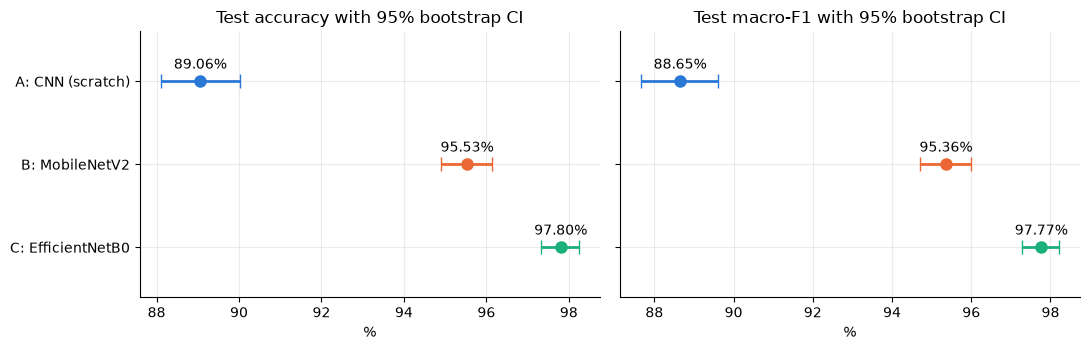

In [4]:
B = 10_000
rng = np.random.default_rng(42)


def bootstrap_scores(cm, n_boot=B):
    """Bootstrap accuracy and macro-F1 by resampling confusion-matrix cells."""
    n = int(cm.sum())
    draws = rng.multinomial(n, cm.ravel() / n, size=n_boot).reshape(
        n_boot, *cm.shape).astype(float)
    tp = np.diagonal(draws, axis1=1, axis2=2)
    with np.errstate(invalid="ignore", divide="ignore"):
        p = np.nan_to_num(tp / draws.sum(axis=1))
        r = np.nan_to_num(tp / draws.sum(axis=2))
        f1 = np.nan_to_num(2 * p * r / (p + r))
    return tp.sum(axis=1) / n, f1.mean(axis=1)


ci_rows = []
for name in MODELS:
    acc_b, f1_b = bootstrap_scores(cms[name])
    ci_rows.append({"model": name,
                    "accuracy": scores[name]["accuracy"],
                    "acc_lo": np.percentile(acc_b, 2.5),
                    "acc_hi": np.percentile(acc_b, 97.5),
                    "macro_f1": scores[name]["f1"].mean(),
                    "f1_lo": np.percentile(f1_b, 2.5),
                    "f1_hi": np.percentile(f1_b, 97.5)})
ci = pd.DataFrame(ci_rows).set_index("model")
comparison = comparison.join(ci[["acc_lo", "acc_hi", "f1_lo", "f1_hi"]])
comparison.to_csv(RESULTS / "model_comparison.csv")
display(ci.style.format("{:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (col, lo, hi, title) in zip(axes, [
        ("accuracy", "acc_lo", "acc_hi", "Test accuracy"),
        ("macro_f1", "f1_lo", "f1_hi", "Test macro-F1")]):
    for y, name in enumerate(MODELS):
        value = ci.loc[name, col]
        ax.errorbar(value * 100, y,
                    xerr=[[(value - ci.loc[name, lo]) * 100],
                          [(ci.loc[name, hi] - value) * 100]],
                    fmt="o", ms=8, capsize=5, lw=2, color=COLORS[name])
        ax.annotate(f"{value:.2%}", (value * 100, y),
                    textcoords="offset points", xytext=(0, 9), ha="center")
    ax.set(title=f"{title} with 95% bootstrap CI", xlabel="%")
    ax.set_yticks(range(len(MODELS)), list(MODELS))
    ax.set_ylim(-0.6, len(MODELS) - 0.4)
    ax.invert_yaxis()
plt.tight_layout()
fig.savefig(RESULTS / "comparison_overall.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Are the differences statistically significant?

**McNemar's test** is the standard way to compare two classifiers on the same
test set (Dietterich, 1998). It only looks at the tiles where the two models
disagree. Let $b$ count the tiles that model 1 gets right and model 2 gets
wrong, and $c$ the reverse. Under $H_0$ (equal error rates),
$b \sim \mathrm{Binomial}(b+c, 0.5)$. McNemar's test needs per-image
predictions. Model C saves them in `efficientnet_test_predictions.csv`, but
Models A and B saved only their confusion matrices.

So, for every pair, I also run an **unpaired two-proportion $z$-test** on
accuracy:
$z = (\hat p_1-\hat p_2)/\sqrt{\bar p(1-\bar p)\,2/N}$. Two models scored on
the same images make correlated errors, and that correlation lowers the true
variance of $\hat p_1-\hat p_2$. So the unpaired test is **conservative**: a
pair that is significant here would also be significant under McNemar's
test. The McNemar cell below runs automatically for any pair whose
`<prefix>_test_predictions.csv` files both exist.

In [5]:
N = 4050
names = list(MODELS)
tests = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        p1, p2 = scores[a]["accuracy"], scores[b]["accuracy"]
        pooled = (p1 + p2) / 2
        z = (p2 - p1) / np.sqrt(pooled * (1 - pooled) * 2 / N)
        tests.append({"comparison": f"{b} vs {a}",
                      "accuracy_gain_pts": (p2 - p1) * 100,
                      "z": z, "p_value": 2 * stats.norm.sf(abs(z))})
tests_df = pd.DataFrame(tests).set_index("comparison")
display(tests_df.style.format({"accuracy_gain_pts": "{:+.2f}", "z": "{:.2f}",
                               "p_value": "{:.2e}"}))

# Paired McNemar test wherever both models saved per-image predictions.
preds = {name: pd.read_csv(path).set_index("filename")
         for name, prefix in MODELS.items()
         if (path := RESULTS / f"{prefix}_test_predictions.csv").exists()}
for i, a in enumerate(names):
    for b in names[i + 1:]:
        if a in preds and b in preds:
            pa, pb = preds[a].align(preds[b], join="inner")
            ok_a, ok_b = pa["label"] == pa["pred"], pb["label"] == pb["pred"]
            n01, n10 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
            p = stats.binomtest(n01, n01 + n10, 0.5).pvalue
            print(f"McNemar {b} vs {a}: b={n01}, c={n10}, p={p:.2e}")
print("Per-image predictions available for:", list(preds) or "none")

,accuracy_gain_pts,z,p_value
comparison,,,
B: MobileNetV2 vs A: CNN (scratch),+6.47,10.92,9.52e-28
C: EfficientNetB0 vs A: CNN (scratch),+8.74,15.88,8.98e-57
C: EfficientNetB0 vs B: MobileNetV2,+2.27,5.69,1.24e-08


Per-image predictions available for: ['C: EfficientNetB0']


## 6. Per-class performance

The overall scores hide where the models differ. The heatmap shows the F1
score for each class and model. The table below it shows which classes gain
the most from transfer learning.

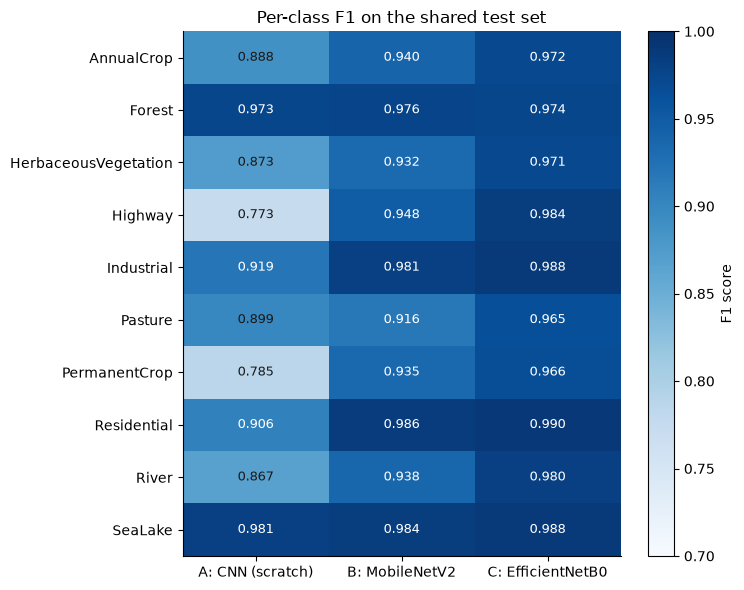

,A: CNN (scratch),B: MobileNetV2,C: EfficientNetB0,F1 gain C vs A,F1 gain C vs B
Highway,0.773,0.948,0.984,0.211,0.037
PermanentCrop,0.785,0.935,0.966,0.181,0.030
River,0.867,0.938,0.980,0.113,0.042
HerbaceousVegetation,0.873,0.932,0.971,0.098,0.039
Residential,0.906,0.986,0.990,0.084,0.004
AnnualCrop,0.888,0.940,0.972,0.084,0.032
Industrial,0.919,0.981,0.988,0.069,0.007
Pasture,0.899,0.916,0.965,0.065,0.048
SeaLake,0.981,0.984,0.988,0.007,0.003
Forest,0.973,0.976,0.974,0.001,-0.002


In [6]:
f1_table = pd.DataFrame({name: scores[name]["f1"] for name in MODELS},
                        index=CLASS_NAMES)
recall_table = pd.DataFrame({name: scores[name]["recall"] for name in MODELS},
                            index=CLASS_NAMES)
f1_table.to_csv(RESULTS / "comparison_per_class_f1.csv")

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(f1_table.to_numpy(), cmap="Blues", vmin=0.7, vmax=1.0,
               aspect="auto")
ax.set_xticks(range(len(MODELS)), list(MODELS))
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.grid(False)
for (r, c), value in np.ndenumerate(f1_table.to_numpy()):
    ax.text(c, r, f"{value:.3f}", ha="center", va="center",
            color="white" if value > 0.9 else "#1a1a19", fontsize=9)
fig.colorbar(im, ax=ax, label="F1 score")
ax.set_title("Per-class F1 on the shared test set")
plt.tight_layout()
fig.savefig(RESULTS / "comparison_per_class_f1.png", dpi=160,
            bbox_inches="tight")
plt.show()

gain = (f1_table["C: EfficientNetB0"] - f1_table["A: CNN (scratch)"]).rename(
    "F1 gain C vs A")
gain_b = (f1_table["C: EfficientNetB0"] - f1_table["B: MobileNetV2"]).rename(
    "F1 gain C vs B")
display(pd.concat([f1_table, gain, gain_b], axis=1)
        .sort_values("F1 gain C vs A", ascending=False)
        .style.format("{:.3f}"))

## 7. Confusion structure: which mistakes are shared?

Each row is normalised to sum to 1, so a cell is the share of that true class
predicted as each label. If a class pair stays confused in **all three**
models, the classes are probably hard to tell apart in 64 × 64 RGB. If only
the scratch CNN confuses a pair, that points to a capacity or feature
problem, which pretraining fixes.

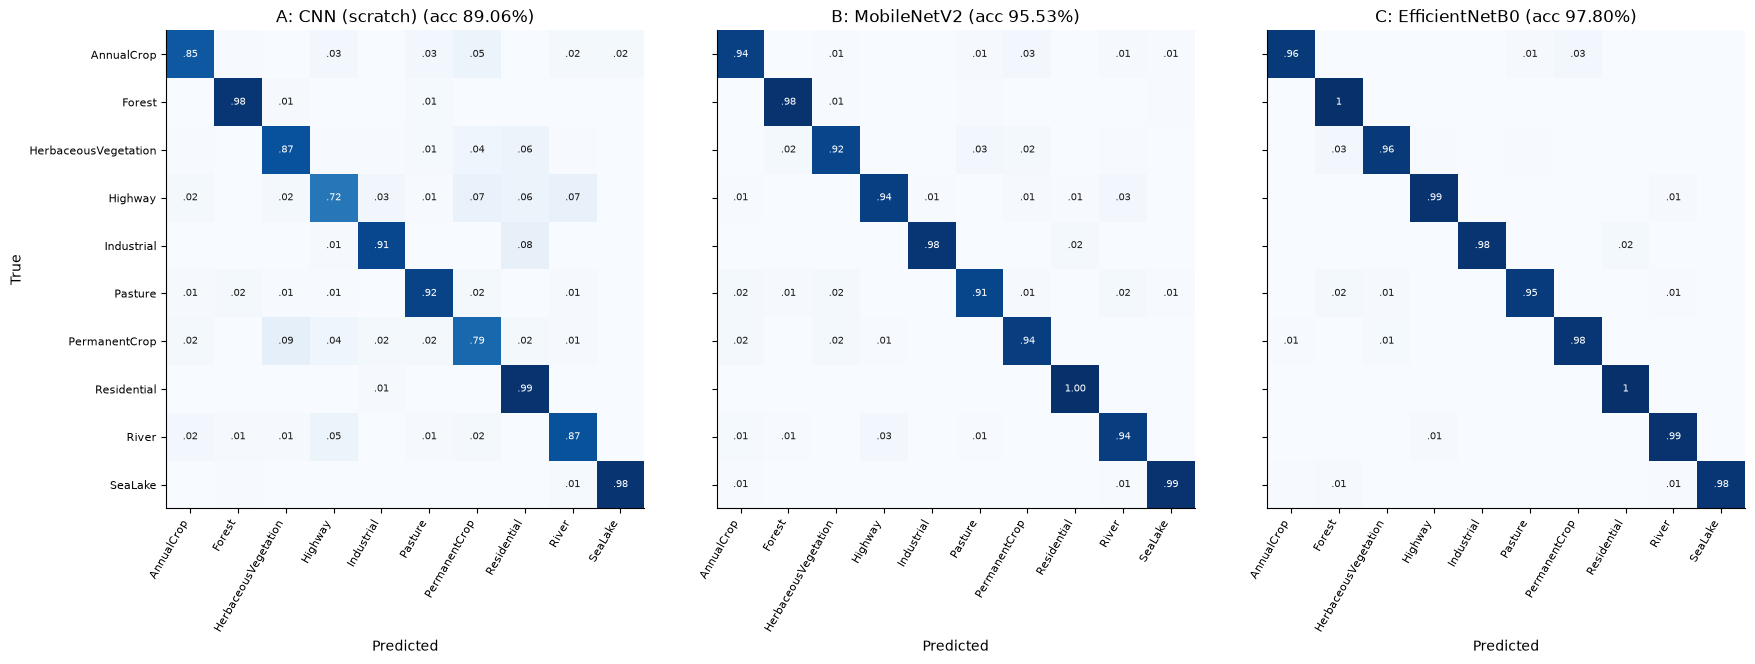

A: CNN (scratch)                                    B: MobileNetV2  \
                   true             predicted count                  true   
0         PermanentCrop  HerbaceousVegetation    35  HerbaceousVegetation   
1            Industrial           Residential    30            AnnualCrop   
2               Highway                 River    28               Highway   
3               Highway         PermanentCrop    26                 River   
4  HerbaceousVegetation           Residential    26  HerbaceousVegetation   
5            AnnualCrop         PermanentCrop    23         PermanentCrop   

                           C: EfficientNetB0                              
       predicted count                  true             predicted count  
0        Pasture    13            AnnualCrop         PermanentCrop    14  
1  PermanentCrop    13  HerbaceousVegetation                Forest    12  
2          River    11            Industrial           Residential     7  
3        Highway    10               Pasture                Forest     6  
4         Forest    10               SeaLake                Forest     5  
5     AnnualCrop     8         PermanentCrop  HerbaceousVegetation     5

Class pairs confused by all three models (errors in both directions):


,A: CNN (scratch),B: MobileNetV2,C: EfficientNetB0
AnnualCrop <-> PermanentCrop,29,21,16
Forest <-> HerbaceousVegetation,5,13,12
Highway <-> River,48,21,7
Industrial <-> Residential,35,8,7
Forest <-> Pasture,12,5,6
HerbaceousVegetation <-> PermanentCrop,53,16,6
HerbaceousVegetation <-> Pasture,8,19,5
Forest <-> SeaLake,2,2,5


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
for ax, name in zip(axes, MODELS):
    norm = cms[name] / cms[name].sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for (r, c), value in np.ndenumerate(norm):
        if value >= 0.005:
            ax.text(c, r, f"{value:.2f}".lstrip("0") if value < 1 else "1",
                    ha="center", va="center", fontsize=7,
                    color="white" if value > 0.6 else "#1a1a19")
    ax.set_xticks(range(10), CLASS_NAMES, rotation=60, ha="right",
                  fontsize=8)
    ax.set_yticks(range(10), CLASS_NAMES if ax is axes[0] else [""] * 10,
                  fontsize=8)
    ax.set_title(f"{name} (acc {scores[name]['accuracy']:.2%})")
    ax.set_xlabel("Predicted")
axes[0].set_ylabel("True")
plt.tight_layout()
fig.savefig(RESULTS / "comparison_confusion.png", dpi=160,
            bbox_inches="tight")
plt.show()


def top_pairs(cm, k=6):
    """Largest off-diagonal (true, predicted) counts."""
    off = cm.copy()
    np.fill_diagonal(off, 0)
    order = np.argsort(off.ravel())[::-1][:k]
    return [(CLASS_NAMES[i // 10], CLASS_NAMES[i % 10], int(off.ravel()[i]))
            for i in order]


pairs = pd.concat({name: pd.DataFrame(top_pairs(cms[name]),
                                      columns=["true", "predicted", "count"])
                   for name in MODELS}, axis=1)
display(pairs)

# Undirected class pairs, summed over both directions, for every model.
pair_errors = {}
for name in MODELS:
    cm = cms[name]
    pair_errors[name] = {f"{CLASS_NAMES[i]} <-> {CLASS_NAMES[j]}":
                         int(cm[i, j] + cm[j, i])
                         for i in range(10) for j in range(i + 1, 10)}
pair_df = pd.DataFrame(pair_errors)
shared = pair_df[(pair_df > 0).all(axis=1)].sort_values(
    "C: EfficientNetB0", ascending=False)
print("Class pairs confused by all three models (errors in both directions):")
display(shared.head(8))

## 8. Training behaviour and efficiency

**Learning curves.** Validation accuracy per epoch for each model. For
Models B and C, the curve includes the frozen-backbone stage and the
fine-tuning stage. The table gives the gap between training and validation
accuracy at the selected epoch, which shows how much each model overfits.

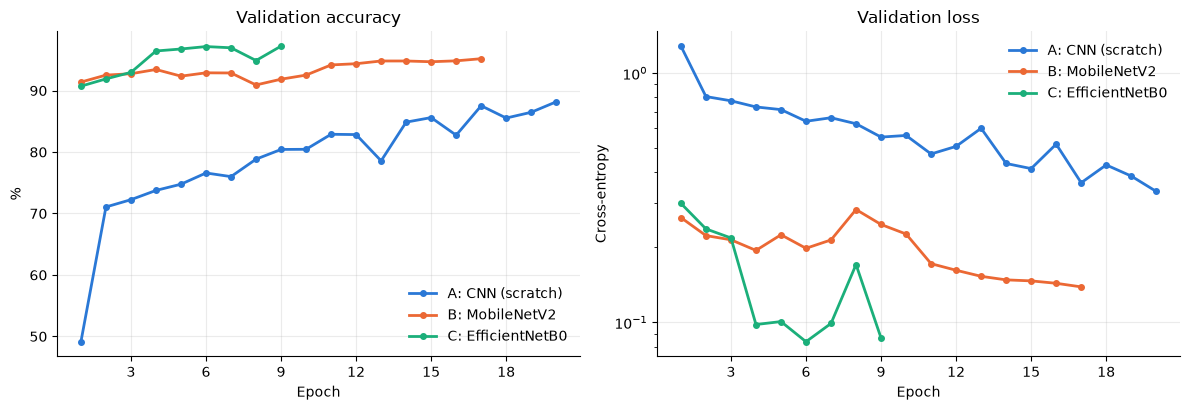

,epochs_trained,selected_epoch,train_acc,val_acc,gap_pts,test_acc
model,,,,,,
A: CNN (scratch),20,20,0.8875,0.8817,+0.58,0.8906
B: MobileNetV2,17,17,0.9713,0.9519,+1.94,0.9553
C: EfficientNetB0,9,6,0.9784,0.9716,+0.68,0.9780


In [8]:
hist_a = pd.read_csv(RESULTS / "cnn_from_scratch_history.csv")
hist_b = pd.read_csv(RESULTS / "mobilenet_history.csv")
hist_b.insert(0, "epoch", np.arange(1, len(hist_b) + 1))
hist_c = pd.read_csv(RESULTS / "efficientnet_history.csv")
histories = dict(zip(MODELS, [hist_a, hist_b, hist_c]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, hist in histories.items():
    axes[0].plot(hist["epoch"], hist["val_accuracy"] * 100, marker="o",
                 ms=4, lw=2, color=COLORS[name], label=name)
    axes[1].plot(hist["epoch"], hist["val_loss"], marker="o", ms=4, lw=2,
                 color=COLORS[name], label=name)
axes[0].set(title="Validation accuracy", xlabel="Epoch", ylabel="%")
axes[1].set(title="Validation loss", xlabel="Epoch",
            ylabel="Cross-entropy")
axes[1].set_yscale("log")
for ax in axes:
    ax.legend(frameon=False)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
fig.savefig(RESULTS / "comparison_learning_curves.png", dpi=160,
            bbox_inches="tight")
plt.show()

gap_rows = []
for name, hist in histories.items():
    best = hist.loc[hist["val_loss"].idxmin()]
    gap_rows.append({"model": name, "epochs_trained": len(hist),
                     "selected_epoch": int(best["epoch"]),
                     "train_acc": best["accuracy"],
                     "val_acc": best["val_accuracy"],
                     "gap_pts": (best["accuracy"] - best["val_accuracy"]) * 100,
                     "test_acc": scores[name]["accuracy"]})
display(pd.DataFrame(gap_rows).set_index("model").style.format(
    {"train_acc": "{:.4f}", "val_acc": "{:.4f}", "gap_pts": "{:+.2f}",
     "test_acc": "{:.4f}"}))

**Accuracy vs. model size.** A bigger model is only worth it if the accuracy
gain justifies the extra cost to store and run it. The x-axis uses a log
scale.

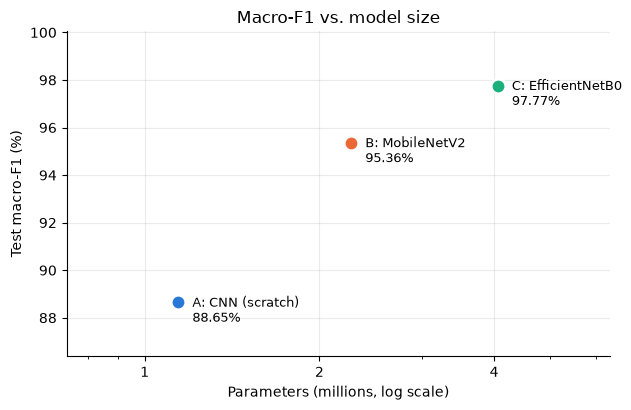

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for name in MODELS:
    x = param_counts[name] / 1e6
    y = scores[name]["f1"].mean() * 100
    ax.scatter(x, y, s=110, color=COLORS[name], edgecolor="white", lw=2,
               zorder=3)
    ax.annotate(f"{name}\n{y:.2f}%", (x, y), textcoords="offset points",
                xytext=(10, -14), fontsize=9)
ax.set_xscale("log")
ax.set_xticks([1, 2, 4, 8], ["1", "2", "4", "8"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set(xlabel="Parameters (millions, log scale)", ylabel="Test macro-F1 (%)",
       title="Macro-F1 vs. model size")
ax.margins(x=0.35, y=0.25)
plt.tight_layout()
fig.savefig(RESULTS / "comparison_size_vs_f1.png", dpi=160,
            bbox_inches="tight")
plt.show()

**Model C robustness.** Model C was trained several times (see notebook 03,
Section 11). I use the seed spread as a second error bar, alongside the
bootstrap interval. The bootstrap interval measures noise from the test
sample, and the seed spread measures noise from training.

In [10]:
runs = pd.read_csv(RESULTS / "efficientnet_runs.csv")
runs["input_size"] = runs["input_size"].astype(int)
seed_runs = runs[runs["input_size"] == 224]
display(runs[["input_size", "seed", "epochs_run", "best_val_accuracy",
              "test_accuracy", "test_macro_f1", "train_minutes"]]
        .sort_values(["input_size", "seed"]).style.format(
            {"best_val_accuracy": "{:.4f}", "test_accuracy": "{:.4f}",
             "test_macro_f1": "{:.4f}", "train_minutes": "{:.1f}"}))
print(f"224 px, {len(seed_runs)} seeds: accuracy "
      f"{seed_runs['test_accuracy'].mean():.4f} ± "
      f"{seed_runs['test_accuracy'].std():.4f} (mean ± SD), "
      f"macro-F1 {seed_runs['test_macro_f1'].mean():.4f} ± "
      f"{seed_runs['test_macro_f1'].std():.4f}")
worst_seed = seed_runs["test_accuracy"].min()
print(f"Worst Model C seed ({worst_seed:.4f}) vs Model B "
      f"({scores['B: MobileNetV2']['accuracy']:.4f}): "
      f"{(worst_seed - scores['B: MobileNetV2']['accuracy']) * 100:+.2f} pts")

,input_size,seed,epochs_run,best_val_accuracy,test_accuracy,test_macro_f1,train_minutes
4,64,42,11.000000,0.9595,0.9637,0.9632,15.2
3,128,42,11.000000,0.9721,0.9760,0.9755,18.9
1,224,7,9.000000,0.9758,0.9822,0.9819,26.4
0,224,42,9.000000,0.9716,0.9780,0.9777,26.6
2,224,123,11.000000,0.9748,0.9790,0.9791,33.9


224 px, 3 seeds: accuracy 0.9798 ± 0.0022 (mean ± SD), macro-F1 0.9795 ± 0.0021
Worst Model C seed (0.9780) vs Model B (0.9553): +2.27 pts


## 9. Findings and model selection

All numbers below come from the shared seed-42 split (4,050 test tiles) and
match the tables above.

| Model | Test accuracy (95% CI) | Macro-F1 (95% CI) | Errors | Weakest class (F1) | Params |
|---|---|---|---|---|---|
| A: CNN (scratch) | 89.06% (88.1–90.0) | 0.8865 (0.877–0.896) | 443 | Highway (0.773) | 1.14 M |
| B: MobileNetV2 | 95.53% (94.9–96.2) | 0.9536 (0.947–0.960) | 181 | Pasture (0.916) | 2.27 M |
| **C: EfficientNetB0** | **97.80% (97.3–98.3)** | **0.9777 (0.973–0.982)** | **89** | Pasture (0.965) | 4.06 M |

**1. Transfer learning is the biggest single gain.** Going from the scratch
CNN to MobileNetV2 adds 6.5 accuracy points ($z=10.9$, $p<10^{-27}$). The
classes that gain most are the ones defined by shape and layout rather than
colour. Highway F1 rises from 0.77 to 0.95, PermanentCrop from 0.79 to 0.94,
and Residential from 0.91 to 0.99. The scratch CNN's three-layer feature
stack cannot reliably separate a thin road from a river, or orchard rows
from meadow. ImageNet features already encode edges and repeated textures.

**2. EfficientNetB0 is significantly better than MobileNetV2.** Model C adds
2.27 accuracy points and halves the error count, from 181 to 89. The 95%
bootstrap intervals do not overlap. The conservative unpaired test gives
$z=5.7$, $p\approx10^{-8}$. The result is also stable across training seeds:
three seeds give 97.98% ± 0.22%, and even the worst seed (97.80%) is 2.3
points above Model B. Model C is the best model on 9 of 10 classes. On the
tenth class, Forest, all three models score between 0.973 and 0.976.

**3. Caveat: recipe vs. architecture.** Models B and C were not fine-tuned
the same way. Model B unfroze only its last 20 layers at a learning rate of
1e-5. Model C unfroze the whole backbone (BatchNorm frozen) at 1e-4. Part of
the 2.3-point gap therefore probably comes from the fine-tuning recipe, not
only from the architecture. A controlled follow-up would be to train
MobileNetV2 with Model C's recipe.

**4. Resolution matters, but less than expected.** Upsampling the 64 px
tiles before the backbone helps: 96.37% at 64 px, 97.60% at 128 px, and
97.80% at 224 px (notebook 03, Section 11). Most of the gain arrives by
128 px, and that run trains in 19 minutes instead of 27. Even at native
64 px, EfficientNetB0 (96.37%) beats MobileNetV2 at 224 px (95.53%).

**5. The remaining errors are mostly ambiguous tiles.** The class pairs
that all three models confuse are AnnualCrop ↔ PermanentCrop, Highway ↔
River, Industrial ↔ Residential, and the vegetation classes (Forest,
Pasture, HerbaceousVegetation). These are semantically close classes in
64 × 64 RGB at 10 m per pixel. Model C reduces most of these pairs; for
example, Highway ↔ River errors fall from 48 to 21 to 7.

Model C's most typical new mistake is predicting **Forest** for dark,
low-texture tiles: SeaLake, Pasture, and HerbaceousVegetation tiles in
shadow or under haze. That is why Forest is its lowest-precision class
(0.949). Its Grad-CAM maps (notebook 03, Section 10) show attention on the
expected structures: the road strip for Highway, the water channel for
River, and building blocks for Industrial. So these errors come from
low-contrast tiles rather than a spurious cue.

**6. Overfitting is under control for every model.** The gap between
training and validation accuracy at the selected epoch is 0.6 points (A),
1.9 points (B), and 0.7 points (C). The test scores sit close to the
validation scores.

### Selected model

**Model C (EfficientNetB0, 224 px input, two-stage fine-tuning)** has the
highest accuracy and macro-F1, the best worst-class F1, and the lowest test
loss. Its advantage is significant across test samples and stable across
training seeds. It costs 1.8× the parameters of MobileNetV2, which is still
small at 4.1 M, and runs inference at about 3.6 ms per tile on our GPU.
If compute is tight, the 128 px variant keeps 97.6% accuracy for about 30%
less training time. If a model must run on a phone or edge device,
MobileNetV2 remains a reasonable fallback at 95.5%.

### Limitations and future work

* **One split.** All models share one stratified 70/15/15 split. The seed
  runs and bootstrap intervals measure training noise and test-sample noise,
  but a k-fold cross-validation would also measure split noise.
* **Spatial leakage.** EuroSAT tiles from the same Sentinel-2 scene can land
  in both the training and test sets. Scene-grouped splits would give a more
  honest estimate for unseen regions.
* **RGB only.** We use 3 of Sentinel-2's 13 bands. Near-infrared bands
  separate vegetation types much better and target the Pasture, Herbaceous,
  and Forest confusions directly.
* **Paired tests.** Models A and B did not save per-image predictions. If
  they save `<prefix>_test_predictions.csv`, Section 5 runs the exact
  McNemar test automatically.
* **Ethics.** Land-cover maps feed decisions on agriculture subsidies,
  zoning, and environmental enforcement. A model trained on European scenes
  may perform worse elsewhere, so it should be validated locally before any
  such use, and a human should review low-confidence tiles.

AI Disclosure: Claude and Gemini models are referred to draft some parts of the notebook but i reviewed, ran and validated the results to meet the expectations of the final project.